In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, confusion_matrix)
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer

# style for plots
plt.style.use('default')
sns.set_palette("colorblind")

**<h1>Dataset description</h1>**

**<h3>Exploratory Data Analysis</h3>**

In [ ]:
# Dataset

heart_df = pd.read_csv('https://raw.githubusercontent.com/Mayen-Shahriar-Kabir/CSE422_Project/refs/heads/main/heart_disease.csv')

print(f"Dataset shape: {heart_df.shape}")
print("\nFirst few rows of the dataset:")
heart_df.head()

Dataset shape: (920, 16)

First few rows of the dataset:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


**<h3>Feature Names and its Datatypes</h3>**

In [ ]:
print("Dataset Information:")
print("=" * 50)
heart_df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


**<h3>Numerical Features</h3>**

In [ ]:
numerical_data = heart_df.select_dtypes(include='number')

numerical_features = numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 8 numerical features: 

['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']


In [ ]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
id,920.0,460.500000,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,53.510870,9.424685,28.0,47.00,54.0,60.00,77.0
trestbps,861.0,132.132404,19.066070,0.0,120.00,130.0,140.00,200.0
chol,890.0,199.130337,110.780810,0.0,175.00,223.0,268.00,603.0
thalch,865.0,137.545665,25.926276,60.0,120.00,140.0,157.00,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.00,0.5,1.50,6.2
ca,309.0,0.676375,0.935653,0.0,0.00,0.0,1.00,3.0
num,920.0,0.995652,1.142693,0.0,0.00,1.0,2.00,4.0


In [ ]:
numerical_data.var()

,0
id,70610.000000
age,88.824691
trestbps,363.515007
chol,12272.387943
thalch,672.171813
oldpeak,1.190775
ca,0.875447
num,1.305748


**Skew**

In [ ]:
numerical_data.skew()

,0
id,0.000000
age,-0.195994
trestbps,0.213334
chol,-0.613836
thalch,-0.211119
oldpeak,1.041427
ca,1.165978
num,0.968880


**<h3>Histogram And Box Plot</h3>**

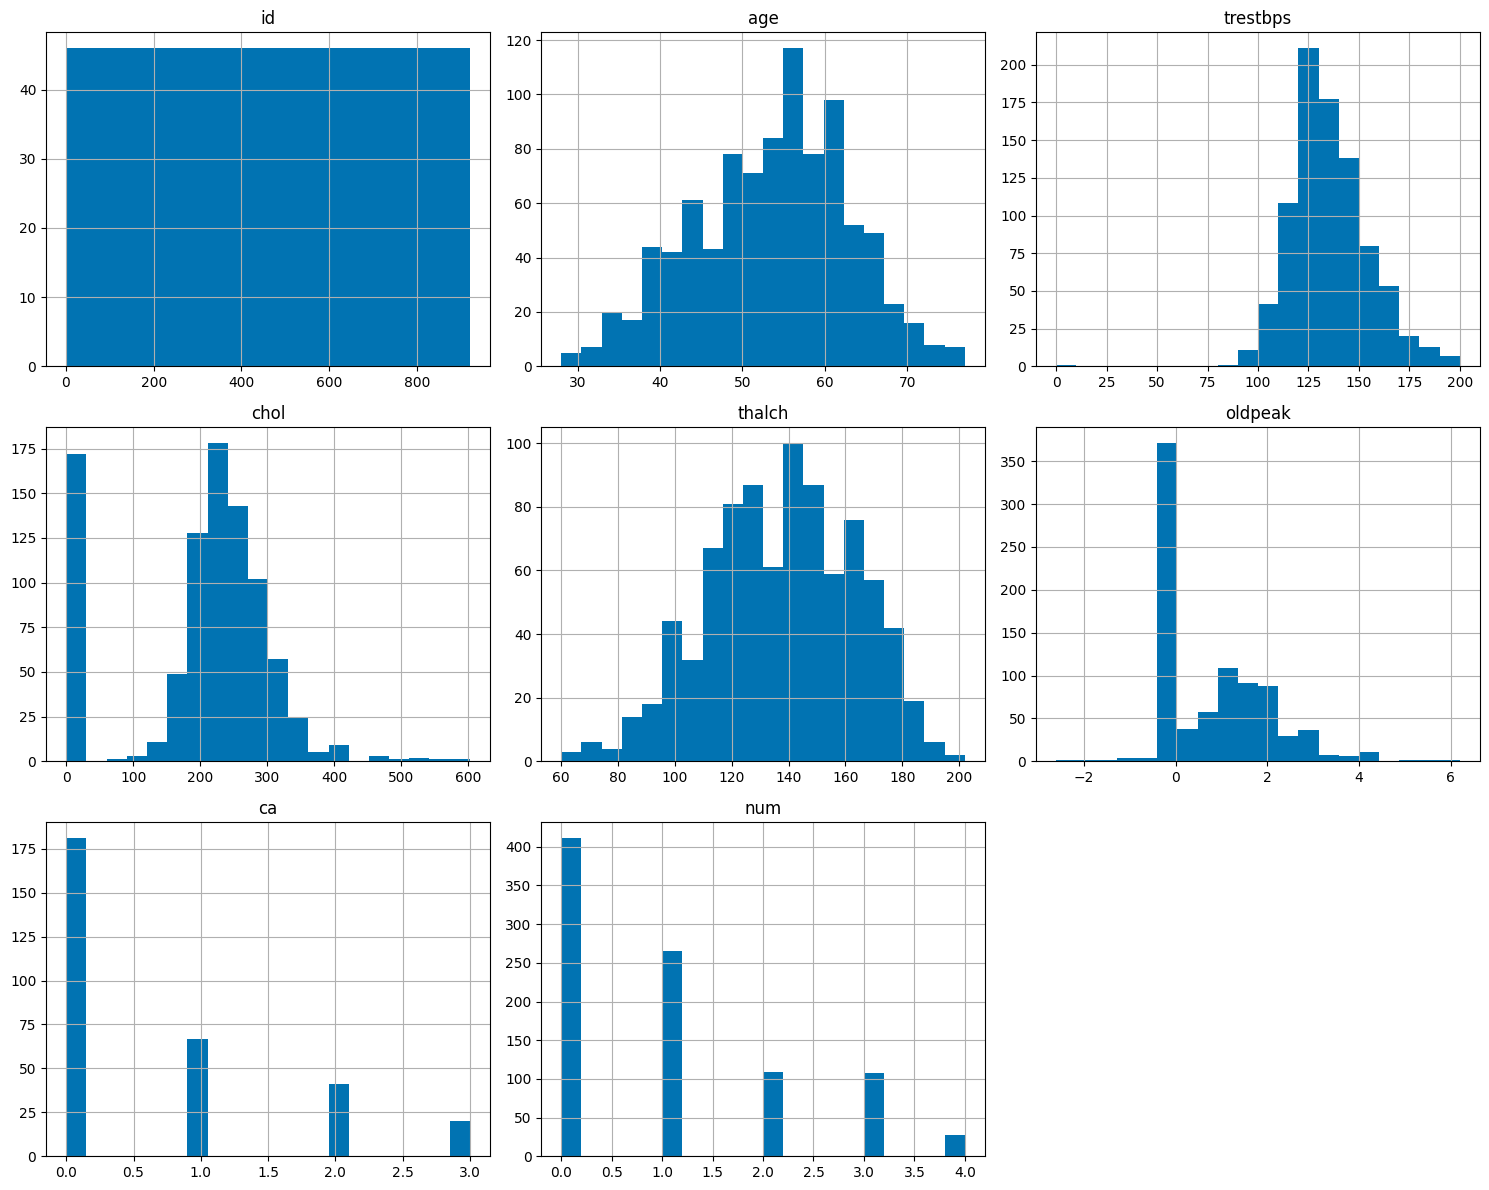

In [ ]:
numerical_data.hist(figsize=(15, 12), bins=20)
plt.tight_layout()
plt.show()

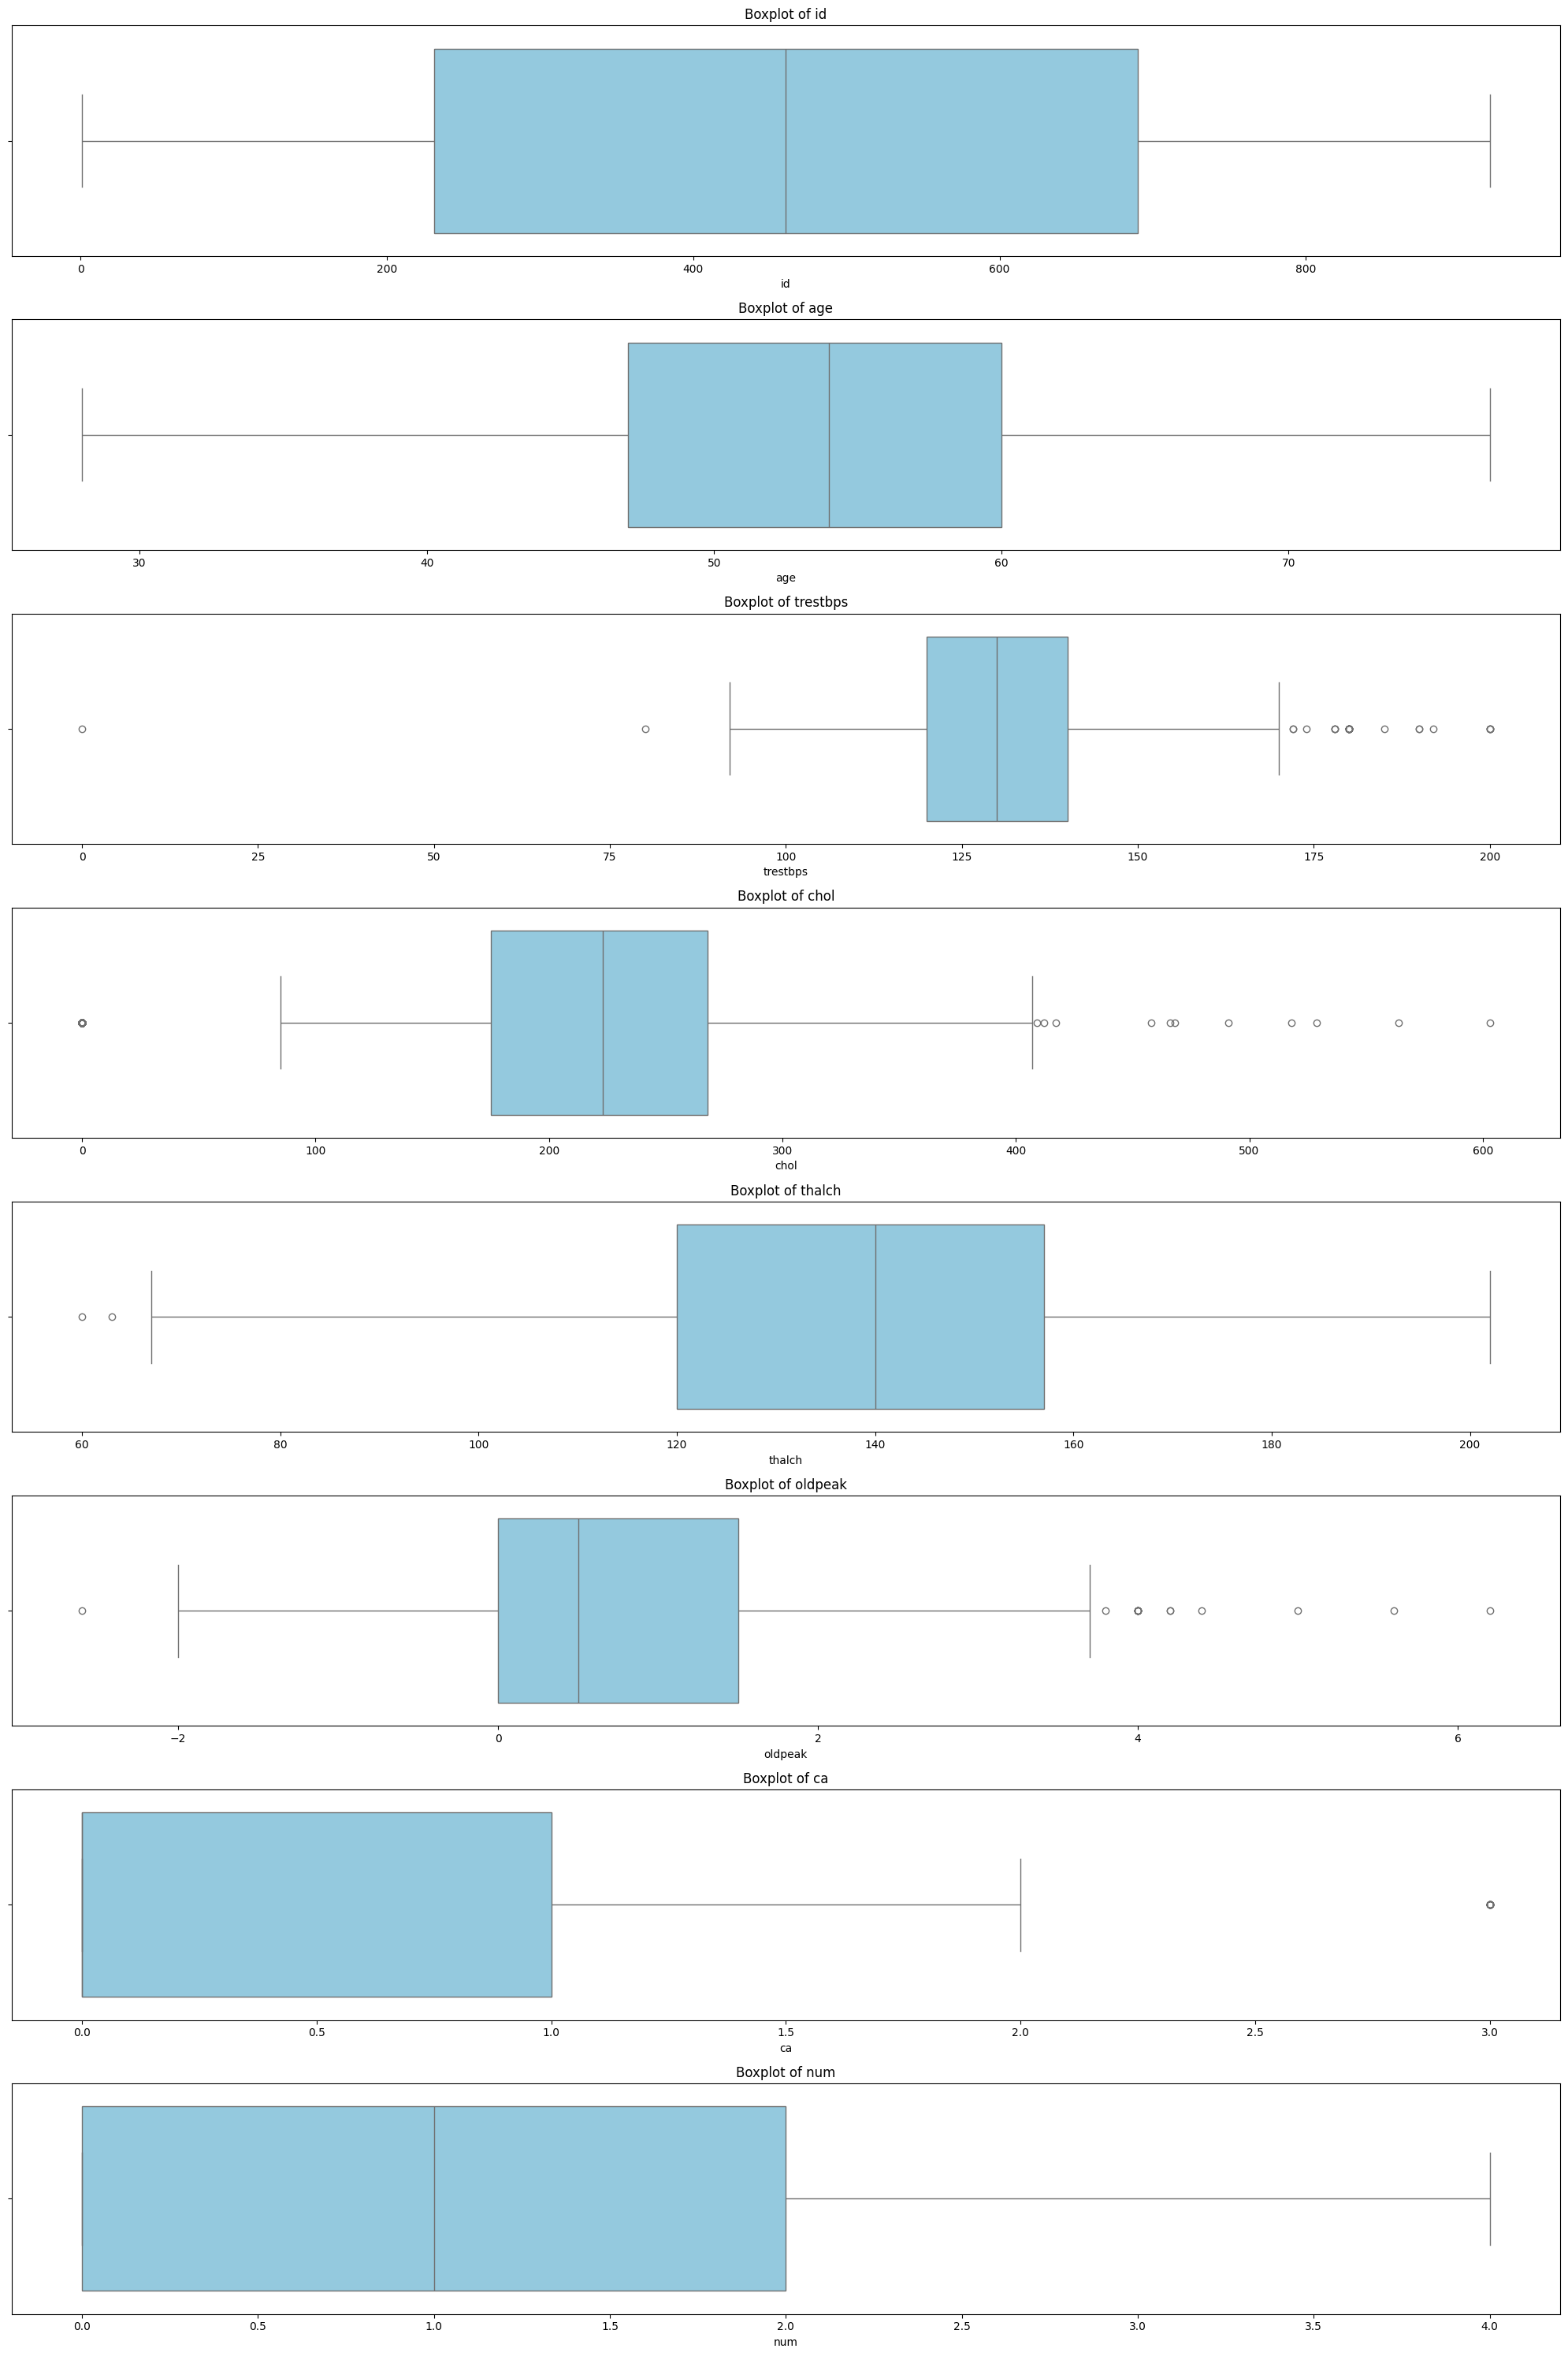

In [ ]:
plt.figure(figsize=(20, 30))
for i, col in enumerate(numerical_features, 1):
    plt.subplot(len(numerical_features), 1, i)
    sns.boxplot(x=heart_df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()
plt.show()

**<h3>Categorical Features</h3>**

In [ ]:
categorical_data = heart_df.select_dtypes(include='object')

categorical_features = categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 8 categorical features: 

['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [ ]:
categorical_data.describe().T

,count,unique,top,freq
sex,920,2,Male,726
dataset,920,4,Cleveland,304
cp,920,4,asymptomatic,496
fbs,830,2,False,692
restecg,918,3,normal,551
exang,865,2,False,528
slope,611,3,flat,345
thal,434,3,normal,196


In [ ]:
# Unique values counts
unique_counts = categorical_data.nunique()
print(unique_counts)

sex        2
dataset    4
cp         4
fbs        2
restecg    3
exang      2
slope      3
thal       3
dtype: int64


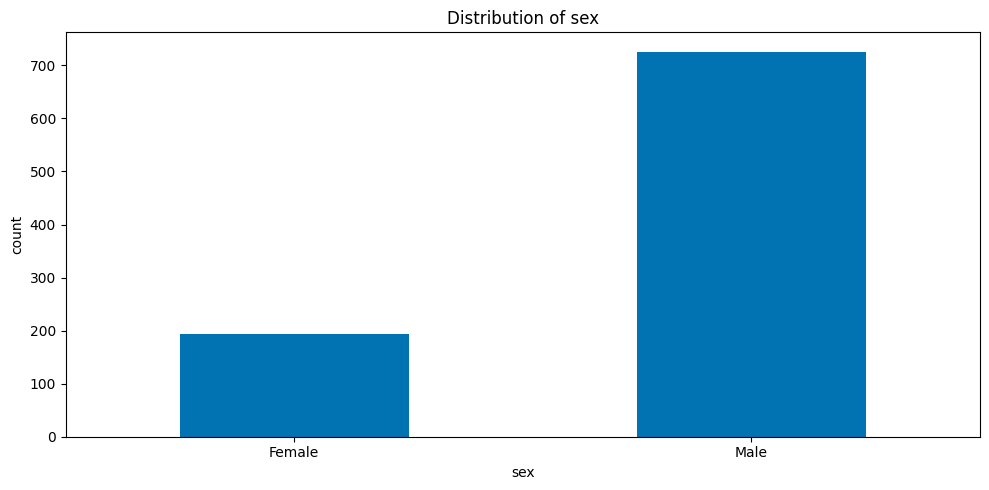

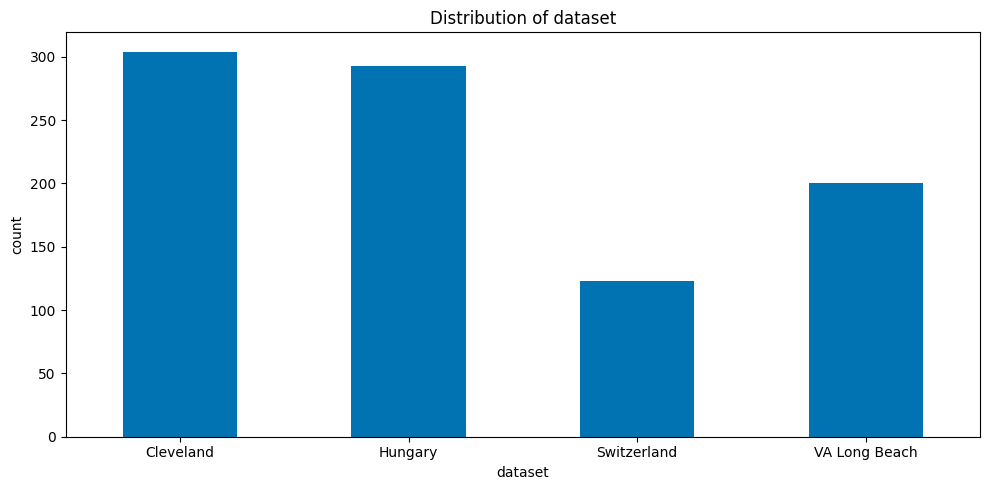

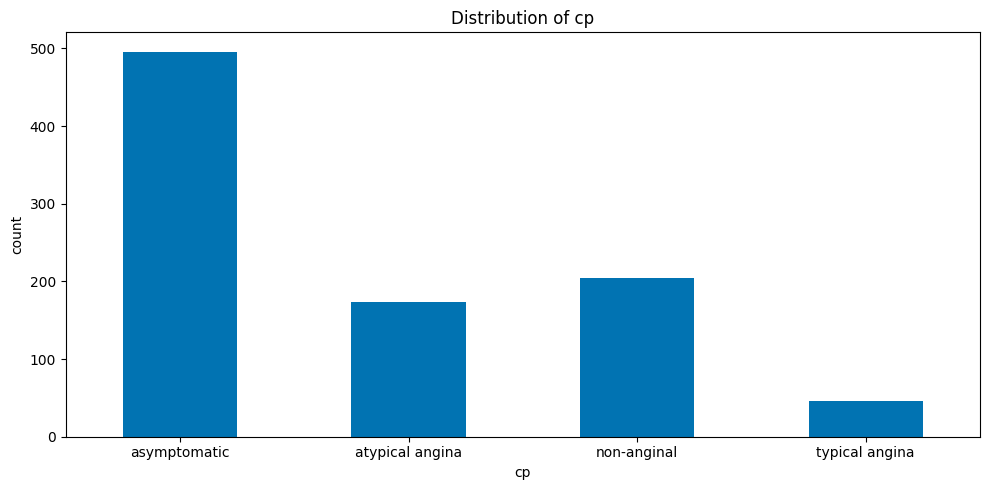

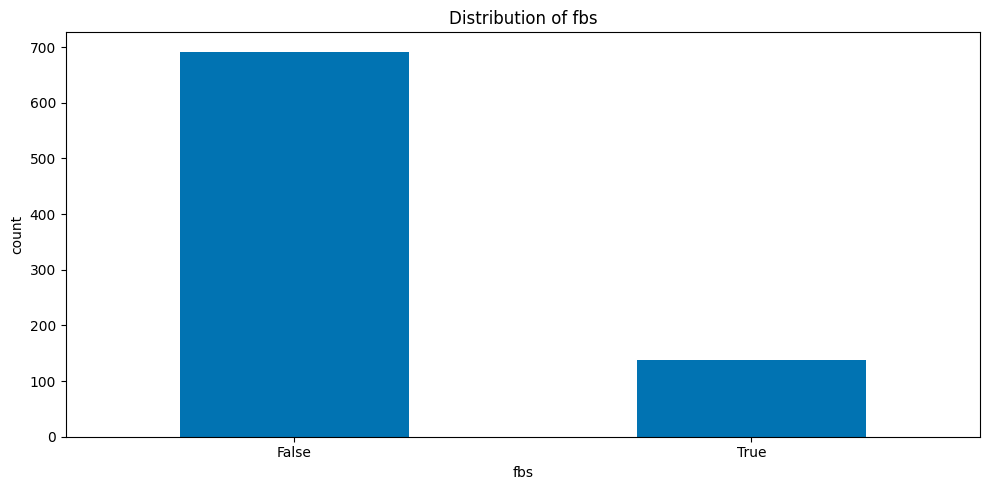

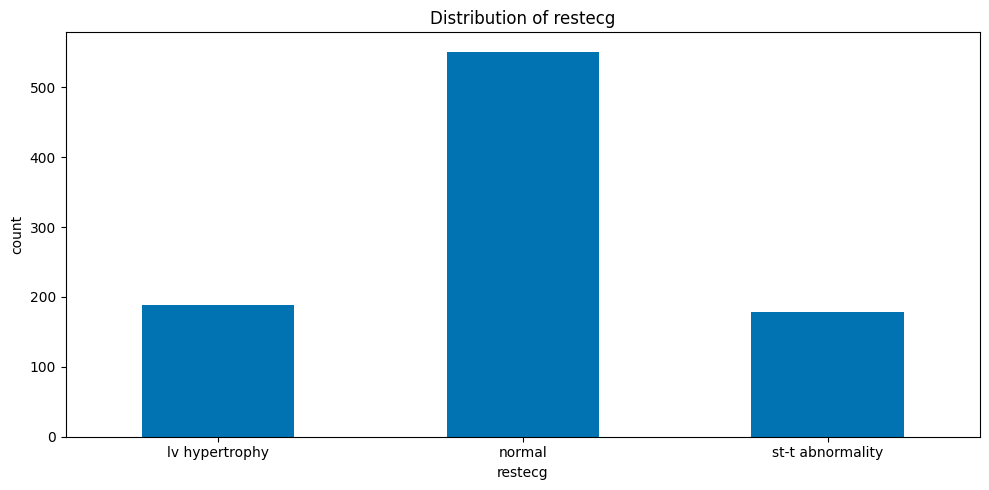

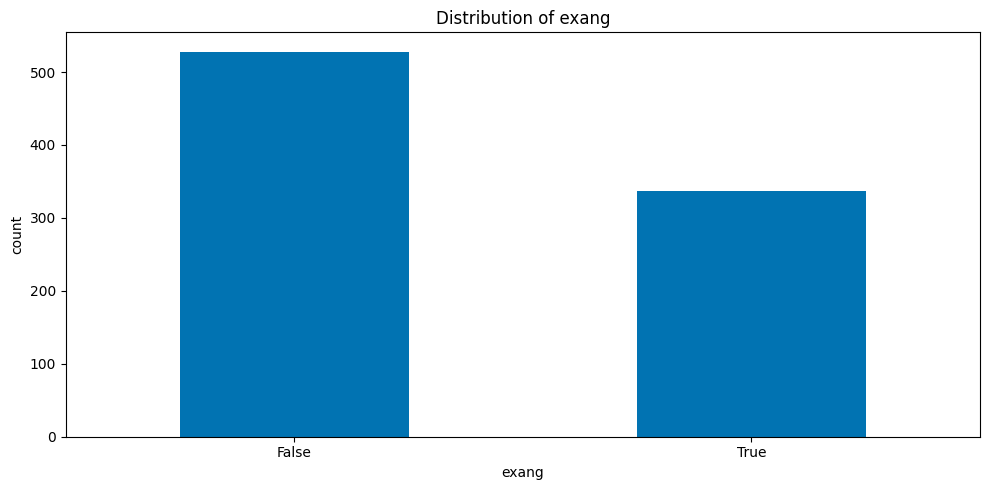

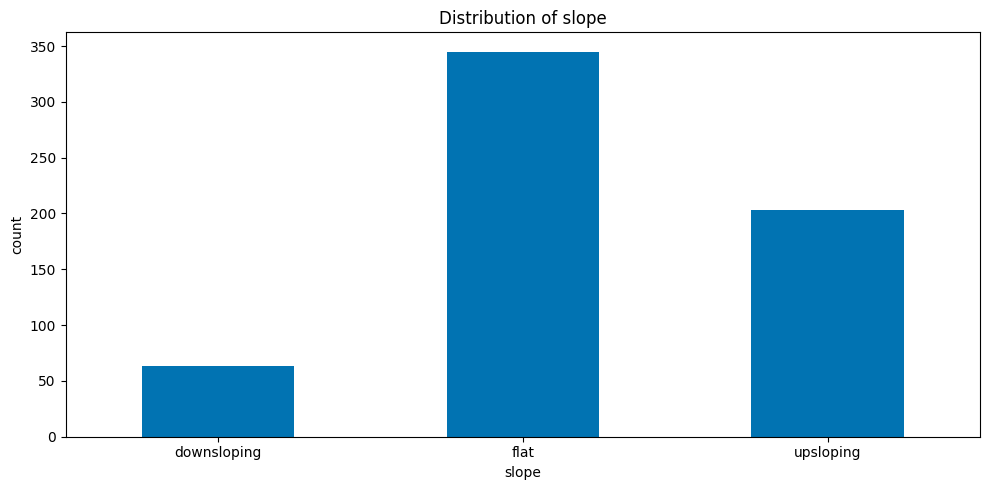

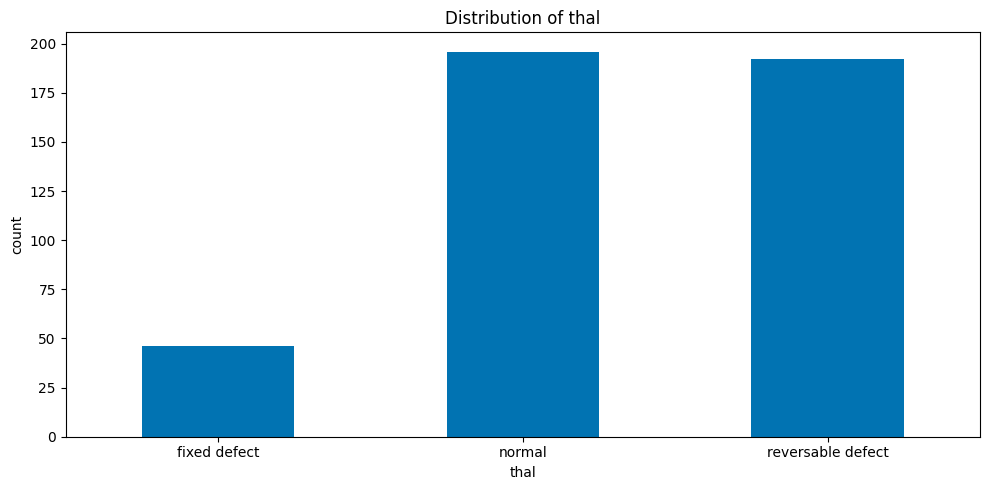

In [ ]:
for col in categorical_features:
    plt.figure(figsize=(10, 5))
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col, ylabel='count')
    plt.tight_layout()
    plt.show()

**<h3>Correlation of the Features & Heatmap</h3>**

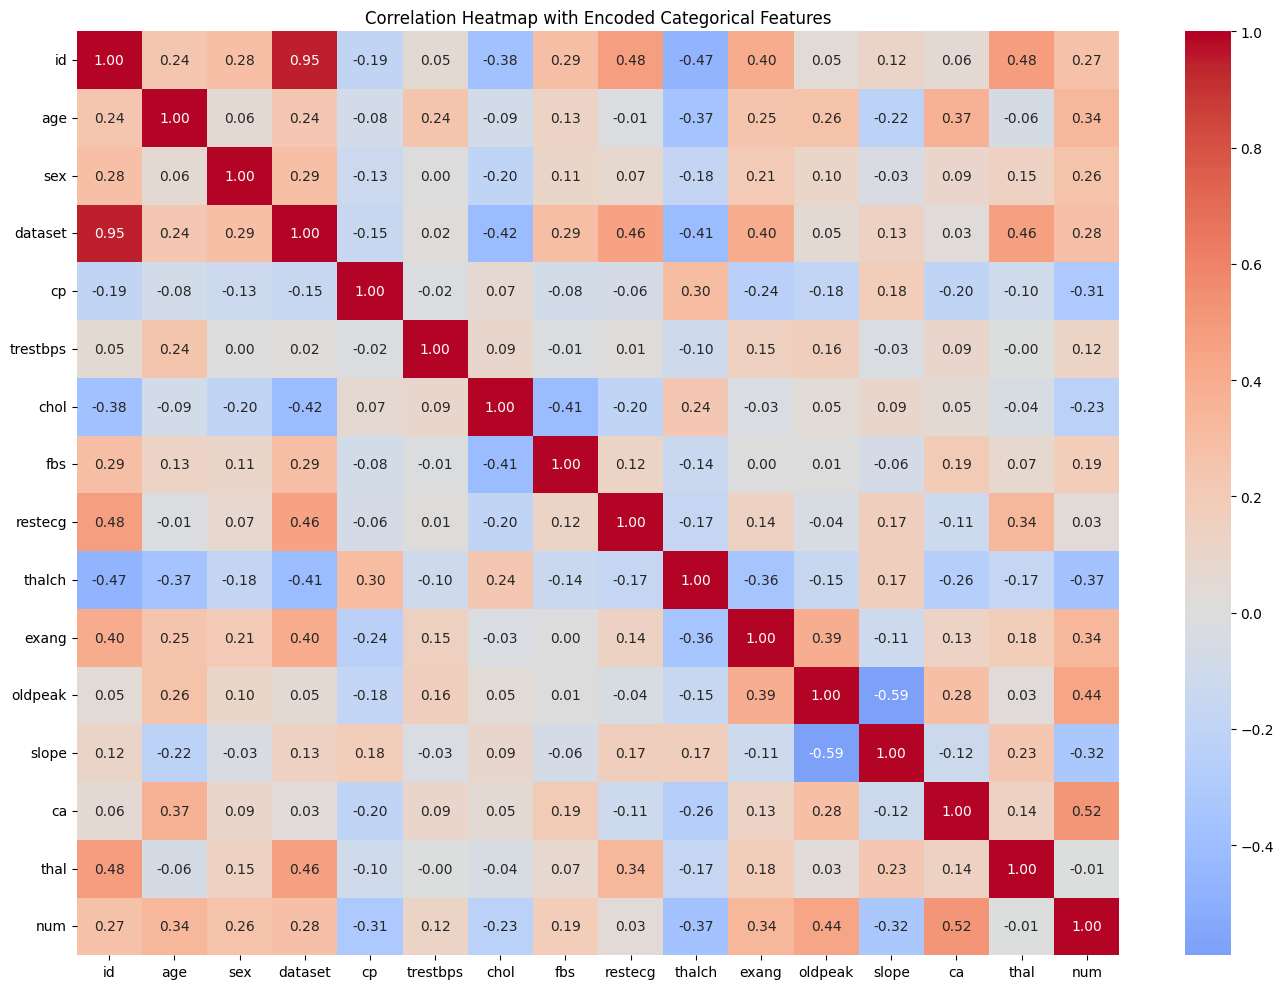

In [ ]:
corr_data = heart_df.copy()

for col in corr_data.select_dtypes(include=['object']).columns:
    corr_data[col] = LabelEncoder().fit_transform(corr_data[col])

corr_matrix = corr_data.corr()

# Heatmap Plot
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title("Correlation Heatmap with Encoded Categorical Features")
plt.tight_layout()
plt.show()

Correlation with target variable (num) using different methods:


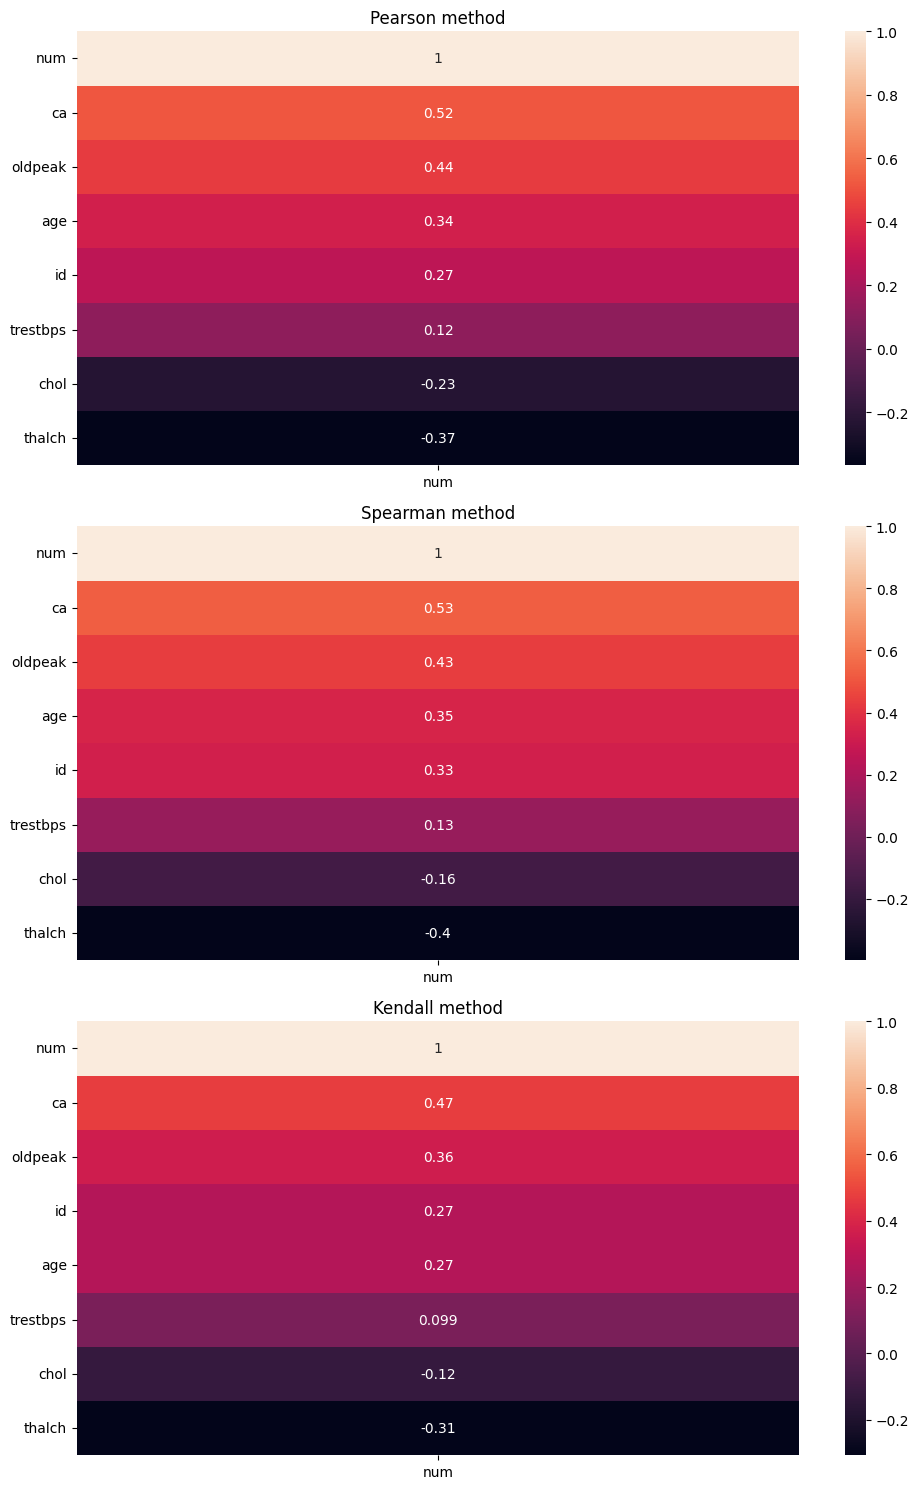

In [ ]:
# Correlation plot between numerical features and target using different methods
print("Correlation with target variable (num) using different methods:")
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

# Pearson correlation
corr1 = numerical_data.corr('pearson')[['num']].sort_values(by='num', ascending=False)
sns.heatmap(corr1, ax=ax[0], annot=True)
ax[0].set_title('Pearson method')

# Spearman correlation
corr2 = numerical_data.corr('spearman')[['num']].sort_values(by='num', ascending=False)
sns.heatmap(corr2, ax=ax[1], annot=True)
ax[1].set_title('Spearman method')

# Kendall correlation
corr3 = numerical_data.corr('kendall')[['num']].sort_values(by='num', ascending=False)
sns.heatmap(corr3, ax=ax[2], annot=True)
ax[2].set_title('Kendall method')

plt.tight_layout()
plt.show()

=== DENSITY PLOTS ===


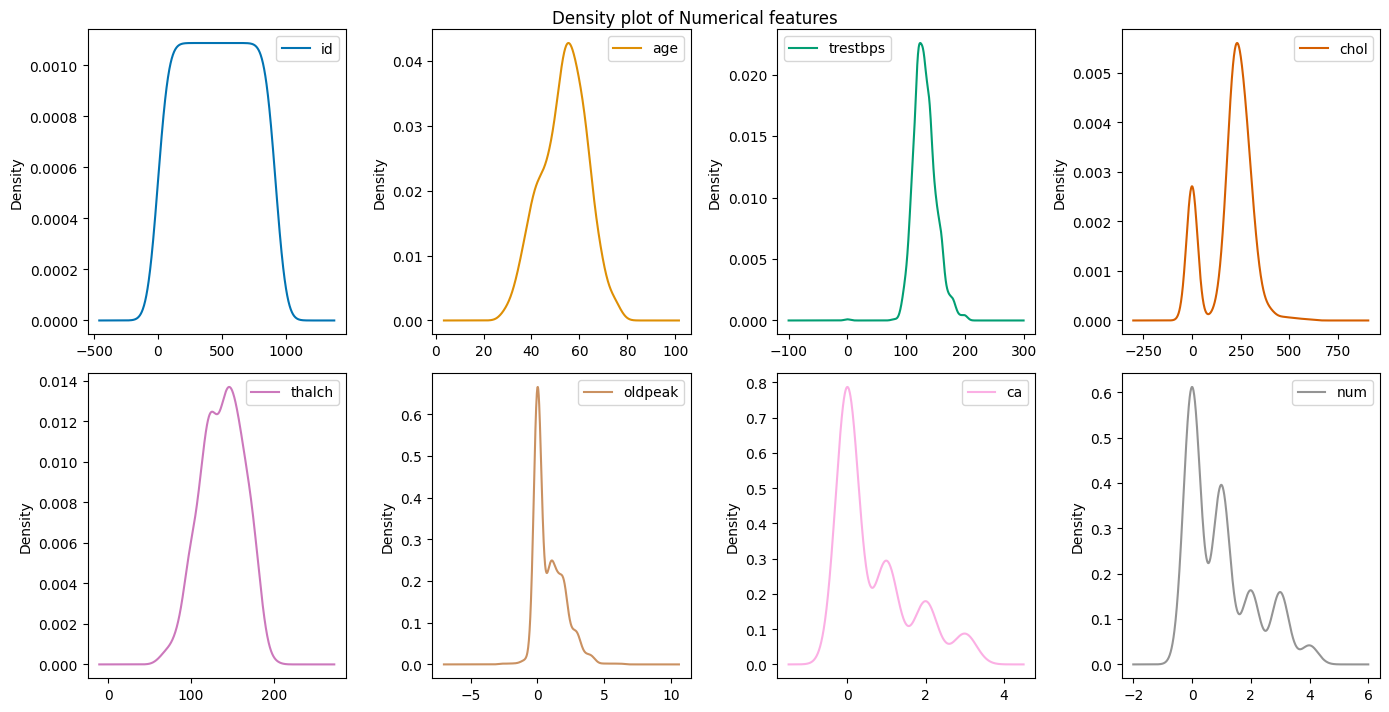

In [ ]:
print("=== DENSITY PLOTS ===")
numerical_data.plot(kind='density', figsize=(14, 14), subplots=True,
                   layout=(4, 4), title="Density plot of Numerical features",
                   sharex=False)
plt.tight_layout()
plt.show()

**<h3>Checking for Imbalance</h3>**

Class distribution:
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


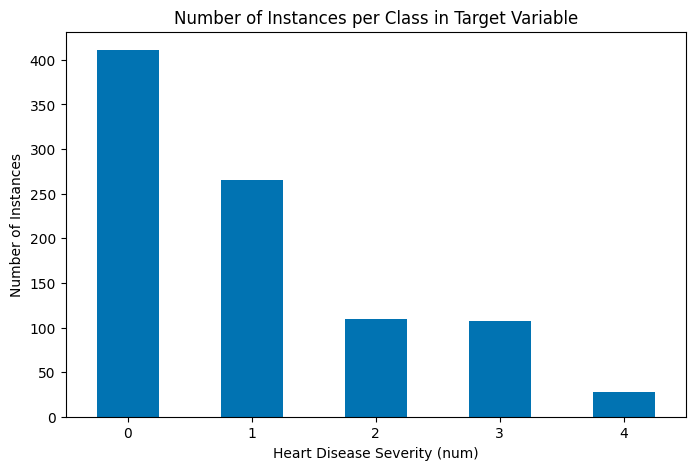

In [ ]:
class_counts = heart_df['num'].value_counts().sort_index()

print("Class distribution:")
print(class_counts)

# Plot bar chart
plt.figure(figsize=(8, 5))
class_counts.plot(kind='bar')
plt.xlabel('Heart Disease Severity (num)')
plt.ylabel('Number of Instances')
plt.title('Number of Instances per Class in Target Variable')
plt.xticks(rotation=0)
plt.show()

**<h1>Dataset pre-processing</h1>**

In [ ]:
print("Shape of dataframe before preprocessing:", heart_df.shape)
heart_df.head()

Shape of dataframe before preprocessing: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [ ]:
print("Missing values in each column:")
heart_df.isnull().sum()

Missing values in each column:


,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55


**Handling Null/Missing values**

In [ ]:
processed_data = heart_df.copy()

print("Dropping 'id' column from processed dataframe...")
processed_data = processed_data.drop('id', axis=1)
print(f"Processed dataframe shape after dropping 'id': {processed_data.shape}")
print()

missing_values = processed_data.isnull().sum()
print("Missing values before handling:")
print(missing_values[missing_values > 0])

# For numerical columns: mean imputation
numerical_cols_with_missing = processed_data.select_dtypes(include=np.number).columns[processed_data.select_dtypes(include=np.number).isnull().any()].tolist()

if numerical_cols_with_missing:
    print(f"Numerical columns with missing values: {numerical_cols_with_missing}")
    imputer = SimpleImputer(strategy='mean')
    processed_data[numerical_cols_with_missing] = imputer.fit_transform(processed_data[numerical_cols_with_missing])

  # For categorical columns: most frequent imputation
categorical_cols_with_missing = processed_data.select_dtypes(include='object').columns[processed_data.select_dtypes(include='object').isnull().any()].tolist()

if categorical_cols_with_missing:
    print(f"Categorical columns with missing values: {categorical_cols_with_missing}")
    imputer = SimpleImputer(strategy='most_frequent')
    processed_data[categorical_cols_with_missing] = imputer.fit_transform(processed_data[categorical_cols_with_missing])

Dropping 'id' column from processed dataframe...
Processed dataframe shape after dropping 'id': (920, 15)

Missing values before handling:
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64
Numerical columns with missing values: ['trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Categorical columns with missing values: ['fbs', 'restecg', 'exang', 'slope', 'thal']


In [ ]:
print("Missing values after handling:")
print(processed_data.isnull().sum().sum())
print()
processed_data.isnull().sum()

Missing values after handling:
0



,0
age,0
sex,0
dataset,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


**Encoding Categorical Values**

In [ ]:
categorical_cols = processed_data.select_dtypes(include='object').columns.tolist()
print("Categorical columns to encode:", categorical_cols)

Categorical columns to encode: ['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [ ]:
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    processed_data[col] = le.fit_transform(processed_data[col].astype(str))
    label_encoders[col] = le

print("After encoding categorical variables:")
processed_data.head()

After encoding categorical variables:


,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,63,1,0,3,145.0,233.0,1,0,150.0,0,2.3,0,0.0,0,0
1,67,1,0,0,160.0,286.0,0,0,108.0,1,1.5,1,3.0,1,2
2,67,1,0,0,120.0,229.0,0,0,129.0,1,2.6,1,2.0,2,1
3,37,1,0,2,130.0,250.0,0,1,187.0,0,3.5,0,0.0,1,0
4,41,0,0,1,130.0,204.0,0,0,172.0,0,1.4,2,0.0,1,0


**Feature Scaling**

In [ ]:
X = processed_data.drop("num", axis=1)
y = processed_data["num"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled, columns=X.columns)

print("After Scaling of the features...")
X.head()

After Scaling of the features...


,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
0,1.007386,0.516931,-1.095558,2.319860,0.698041,0.311021,2.380476,-1.567991,0.495698,-0.760292,1.349421,-2.234081,-1.249371,-2.397813
1,1.432034,0.516931,-1.095558,-0.818774,1.511761,0.797713,-0.420084,-1.567991,-1.175955,1.315283,0.589832,-0.295067,4.292099,-0.328406
2,1.432034,0.516931,-1.095558,-0.818774,-0.658158,0.274289,-0.420084,-1.567991,-0.340128,1.315283,1.634267,-0.295067,2.444942,1.741001
3,-1.752828,0.516931,-1.095558,1.273649,-0.115679,0.467130,-0.420084,0.015491,1.968345,-0.760292,2.488805,-2.234081,-1.249371,-0.328406
4,-1.328180,-1.934494,-1.095558,0.227437,-0.115679,0.044717,-0.420084,-1.567991,1.371326,-0.760292,0.494884,1.643946,-1.249371,-0.328406


**<h1>Dataset Splitting</h1>**

In [ ]:
# First split: separate test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Second split: separate validation from training
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, stratify=y_train_val, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

print("\nClass distribution in splits:")
for split_name, split_y in [('Training', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f"{split_name}:")
    for cls in sorted(split_y.unique()):
        count = (split_y == cls).sum()
        percentage = count / len(split_y) * 100
        print(f"  Class {cls}: {count} samples ({percentage:.1f}%)")

Training set: 588 samples
Validation set: 148 samples
Test set: 184 samples

Class distribution in splits:
Training:
  Class 0: 263 samples (44.7%)
  Class 1: 169 samples (28.7%)
  Class 2: 69 samples (11.7%)
  Class 3: 69 samples (11.7%)
  Class 4: 18 samples (3.1%)
Validation:
  Class 0: 66 samples (44.6%)
  Class 1: 43 samples (29.1%)
  Class 2: 18 samples (12.2%)
  Class 3: 17 samples (11.5%)
  Class 4: 4 samples (2.7%)
Test:
  Class 0: 82 samples (44.6%)
  Class 1: 53 samples (28.8%)
  Class 2: 22 samples (12.0%)
  Class 3: 21 samples (11.4%)
  Class 4: 6 samples (3.3%)


**<h1>Model training & testing (Supervised)</h1>**

In [ ]:
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test) if hasattr(model, "predict_proba") else None

    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, average='weighted', zero_division=0)
    }

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # ROC AUC
    roc_auc = {}
    if y_prob is not None:
        n_classes = y_prob.shape[1]
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve((y_test == i).astype(int), y_prob[:, i])
            roc_auc[f'Class_{i}'] = auc(fpr, tpr)

    return metrics, cm, roc_auc

model_results = {}

"""### 5.1 K-Nearest Neighbors (KNN)"""

print("Training K-Nearest Neighbors model...")

# Hyperparameter tuning for KNN
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]  # 1: Manhattan distance, 2: Euclidean distance
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

knn_grid.fit(X_train, y_train)

# Get best model
best_knn = knn_grid.best_estimator_
print(f"Best KNN parameters: {knn_grid.best_params_}")

# Evaluate on validation set
knn_metrics, knn_cm, knn_auc = evaluate_model(best_knn, X_val, y_val, "KNN")

print("KNN Validation Performance:")
for metric, value in knn_metrics.items():
    print(f"{metric}: {value:.4f}")

# Store results
model_results['KNN'] = {
    'model': best_knn,
    'metrics': knn_metrics,
    'confusion_matrix': knn_cm,
    'auc_scores': knn_auc,
    'best_params': knn_grid.best_params_
}

"""### 5.2 Logistic Regression"""

print("\nTraining Logistic Regression model...")

# Hyperparameter tuning for Logistic Regression
lr_param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [1000]
}

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    lr_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train, y_train)

# Get best model
best_lr = lr_grid.best_estimator_
print(f"Best Logistic Regression parameters: {lr_grid.best_params_}")

# Evaluate on validation set
lr_metrics, lr_cm, lr_auc = evaluate_model(best_lr, X_val, y_val, "Logistic Regression")

print("Logistic Regression Validation Performance:")
for metric, value in lr_metrics.items():
    print(f"{metric}: {value:.4f}")

# Store results
model_results['Logistic Regression'] = {
    'model': best_lr,
    'metrics': lr_metrics,
    'confusion_matrix': lr_cm,
    'auc_scores': lr_auc,
    'best_params': lr_grid.best_params_
}

"""### 5.3 Neural Network"""

print("\nTraining Neural Network model...")

# Hyperparameter tuning for Neural Network
nn_param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01],
    'max_iter': [1000]
}

nn_grid = GridSearchCV(
    MLPClassifier(random_state=42),
    nn_param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

nn_grid.fit(X_train, y_train)

# Get best model
best_nn = nn_grid.best_estimator_
print(f"Best Neural Network parameters: {nn_grid.best_params_}")

# Evaluate on validation set
nn_metrics, nn_cm, nn_auc = evaluate_model(best_nn, X_val, y_val, "Neural Network")

print("Neural Network Validation Performance:")
for metric, value in nn_metrics.items():
    print(f"{metric}: {value:.4f}")

# Store results
model_results['Neural Network'] = {
    'model': best_nn,
    'metrics': nn_metrics,
    'confusion_matrix': nn_cm,
    'auc_scores': nn_auc,
    'best_params': nn_grid.best_params_
}

Training K-Nearest Neighbors model...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best KNN parameters: {'n_neighbors': 13, 'p': 1, 'weights': 'distance'}
KNN Validation Performance:
Accuracy: 0.5676
Precision: 0.5348
Recall: 0.5676
F1-Score: 0.5492

Training Logistic Regression model...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Logistic Regression parameters: {'C': 0.01, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'liblinear'}
Logistic Regression Validation Performance:
Accuracy: 0.6081
Precision: 0.5142
Recall: 0.6081
F1-Score: 0.5551

Training Neural Network model...
Fitting 3 folds for each of 48 candidates, totalling 144 fits
Best Neural Network parameters: {'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (100,), 'learning_rate_init': 0.001, 'max_iter': 1000}
Neural Network Validation Performance:
Accuracy: 0.5000
Precision: 0.5070
Recall: 0.5000
F1-Score: 0.5029


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


**Unsupervised Learning**

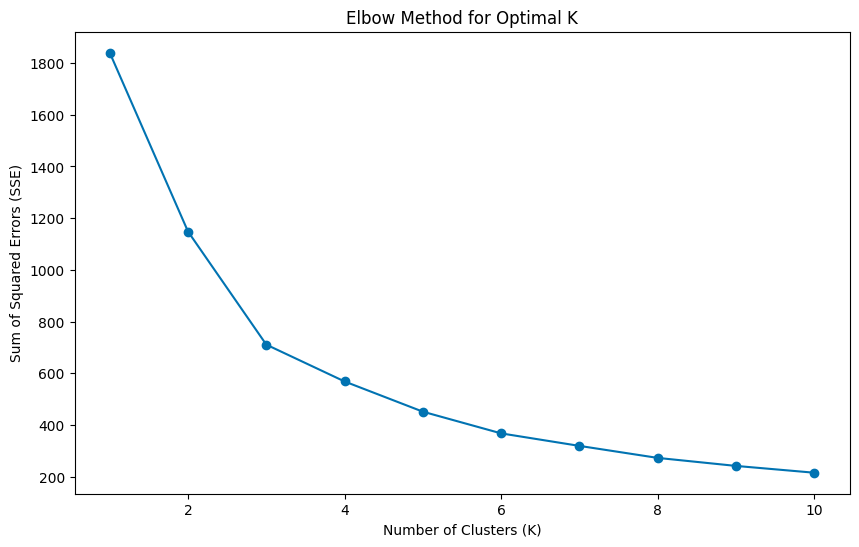

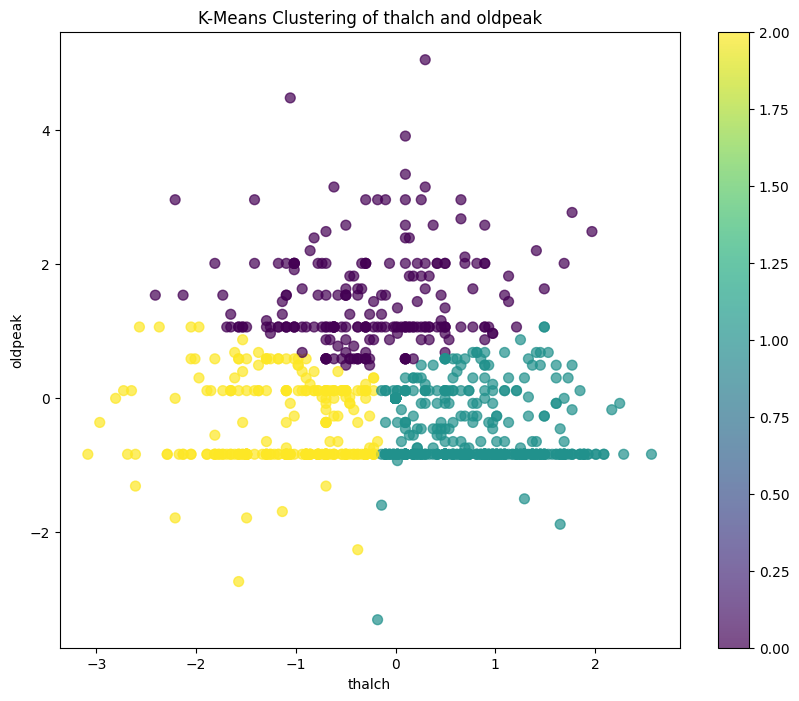

The K-Means algorithm has clustered the data into 3 groups.


In [ ]:
feature1 = 'thalch'
feature2 = 'oldpeak'

if feature1 in X.columns and feature2 in X.columns:
    kmeans_df = X[[feature1, feature2]]

    # Finding the best number of clusters using elbow method
    k_range = range(1, 11)
    SSE = []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        km.fit(kmeans_df)
        SSE.append(km.inertia_)

    plt.figure(figsize=(10, 6))
    plt.plot(k_range, SSE, marker='o')
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Sum of Squared Errors (SSE)")
    plt.title("Elbow Method for Optimal K")
    plt.show()

    k = 3
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(kmeans_df)

    # clusters
    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(
        kmeans_df[feature1],
        kmeans_df[feature2],
        c=kmeans_labels,
        cmap="viridis",
        s=50,
        alpha=0.7
    )
    plt.colorbar(scatter)
    plt.title(f"K-Means Clustering of {feature1} and {feature2}")
    plt.xlabel(feature1)
    plt.ylabel(feature2)
    plt.show()

    print(f"The K-Means algorithm has clustered the data into {k} groups.")
else:
    print("Selected features for clustering not found in the dataset.")

**<h1>Model selection/Comparison analysis</h1>**

Final Model Comparison on Test Set

KNN Test Performance:
Accuracy: 0.5978
Precision: 0.5490
Recall: 0.5978
F1-Score: 0.5713

Logistic Regression Test Performance:
Accuracy: 0.5815
Precision: 0.4722
Recall: 0.5815
F1-Score: 0.5198

Neural Network Test Performance:
Accuracy: 0.5326
Precision: 0.5384
Recall: 0.5326
F1-Score: 0.5347

Model Comparison Summary:
                     Accuracy  Precision    Recall  F1-Score
Model                                                       
KNN                  0.597826   0.549010  0.597826  0.571264
Logistic Regression  0.581522   0.472159  0.581522  0.519826
Neural Network       0.532609   0.538419  0.532609  0.534690


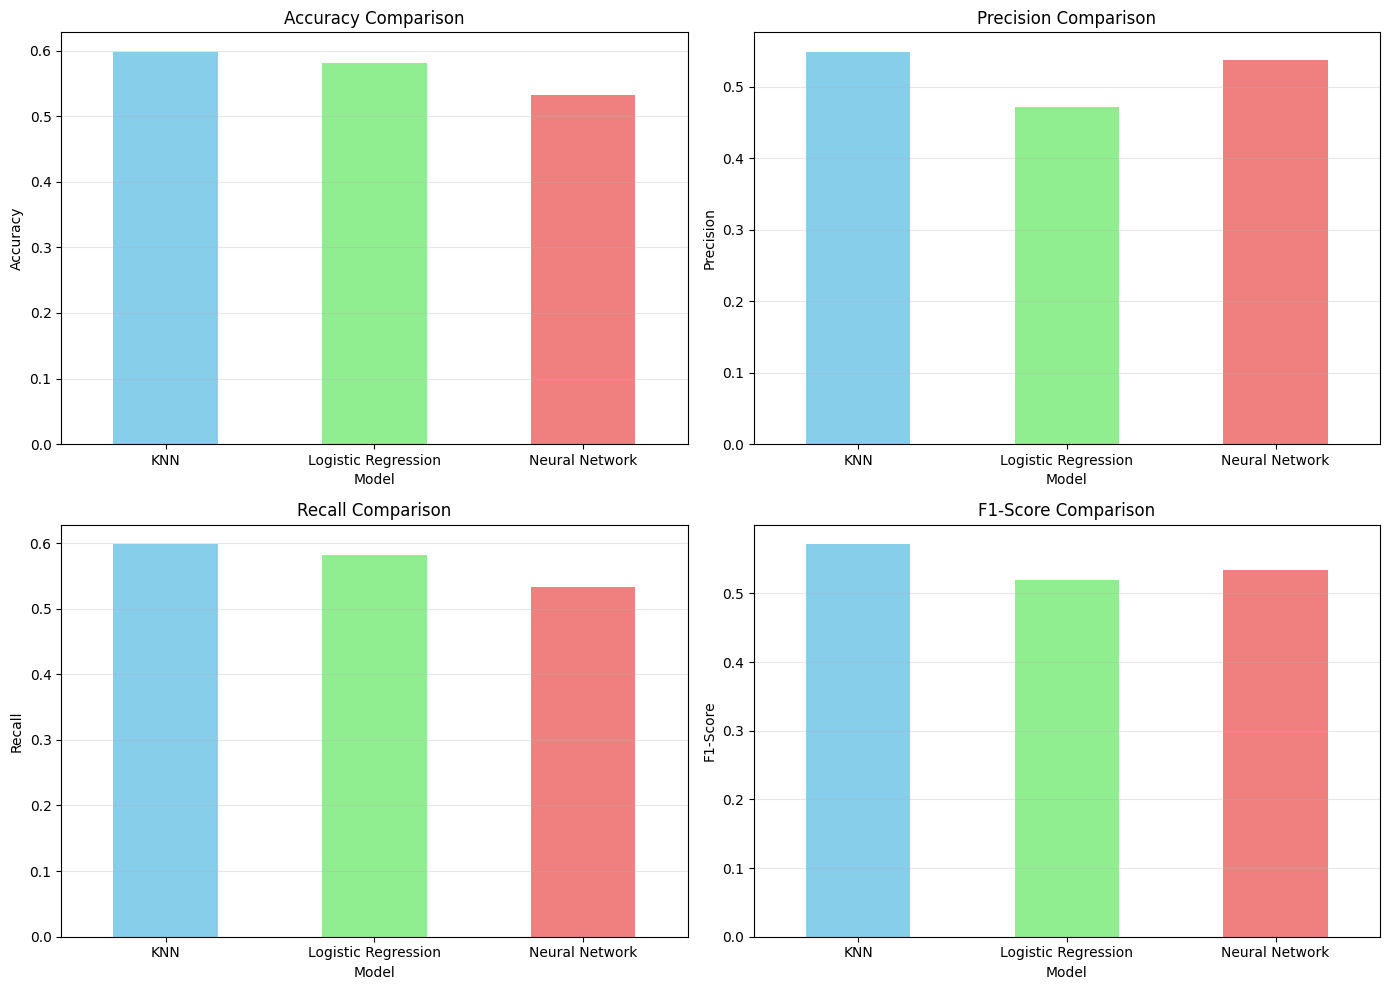

In [ ]:
print("Final Model Comparison on Test Set")
print("=" * 40)

# Evaluate all models on test set
final_results = {}

for model_name, result in model_results.items():
    model = result['model']
    metrics, cm, auc_scores = evaluate_model(model, X_test, y_test, model_name)

    final_results[model_name] = {
        'metrics': metrics,
        'confusion_matrix': cm,
        'auc_scores': auc_scores
    }

    print(f"\n{model_name} Test Performance:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

# comparison dataframe
comparison_data = []
for model_name, results in final_results.items():
    row = {'Model': model_name}
    row.update(results['metrics'])
    comparison_data.append(row)

comparison_df = pd.DataFrame(comparison_data)
comparison_df.set_index('Model', inplace=True)

print("\nModel Comparison Summary:")
print("=" * 30)
print(comparison_df)

# performance comparison
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, metric in enumerate(metrics_to_plot):
    comparison_df[metric].plot(kind='bar', ax=axes[i], color=['skyblue', 'lightgreen', 'lightcoral'])
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Confusion Matrices**

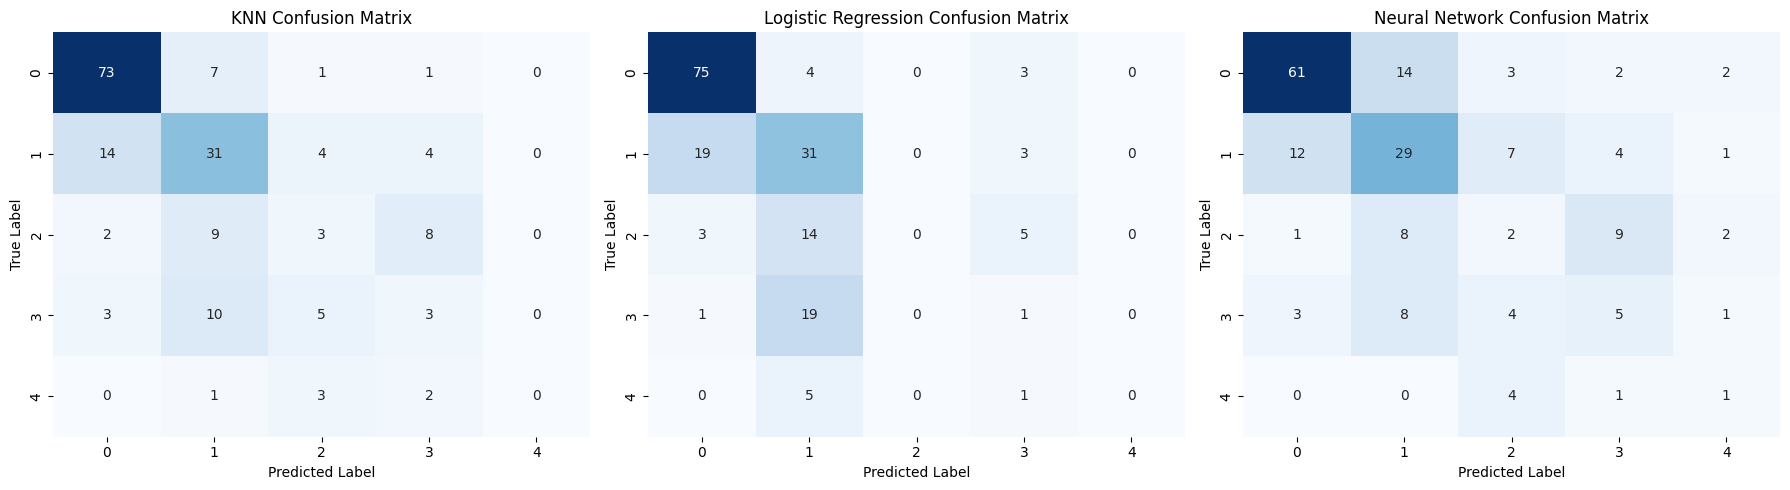

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (model_name, results) in enumerate(final_results.items()):
    sns.heatmap(results['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
                ax=axes[i], cbar=False)
    axes[i].set_title(f'{model_name} Confusion Matrix')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

**AUC score and ROC curve**


ROC Curve Analysis:


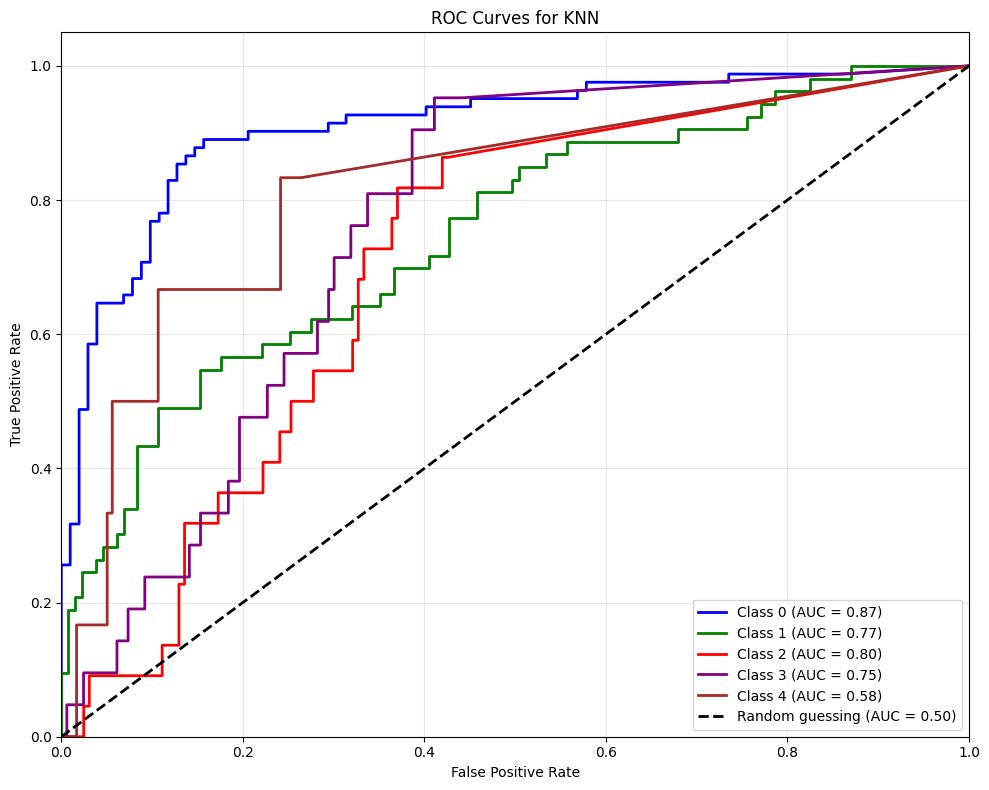

AUC Scores for KNN:
  Class_0: 0.8707
  Class_1: 0.7690
  Class_2: 0.7996
  Class_3: 0.7472
  Class_4: 0.5781


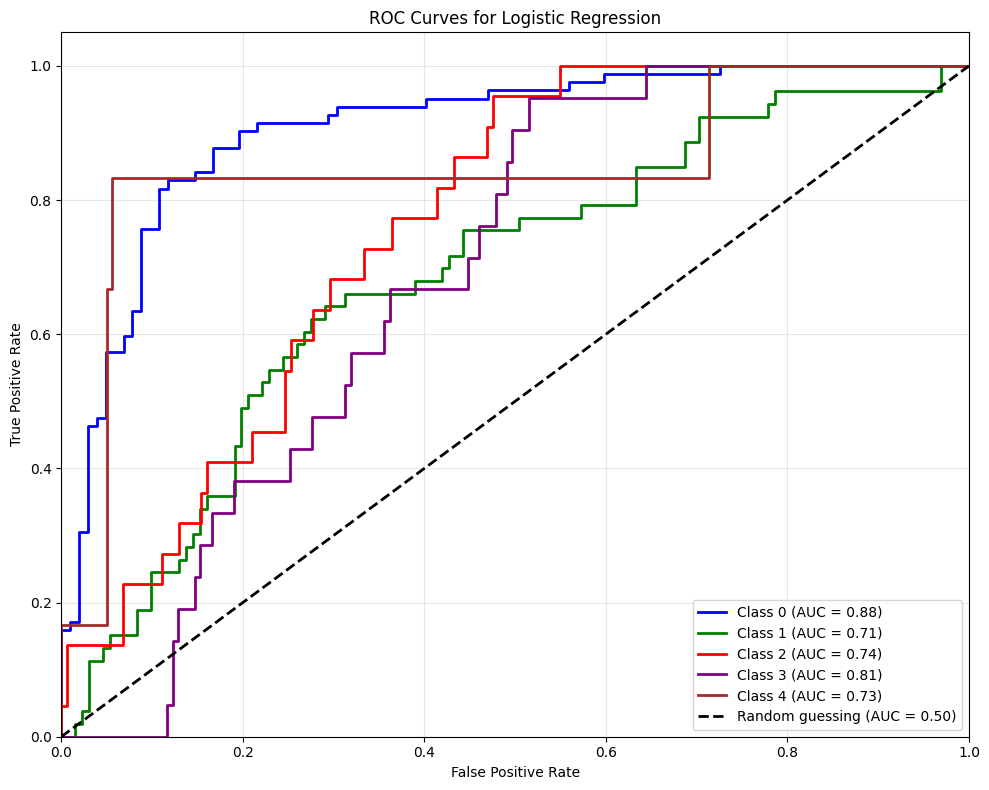

AUC Scores for Logistic Regression:
  Class_0: 0.8758
  Class_1: 0.7101
  Class_2: 0.7410
  Class_3: 0.8087
  Class_4: 0.7257


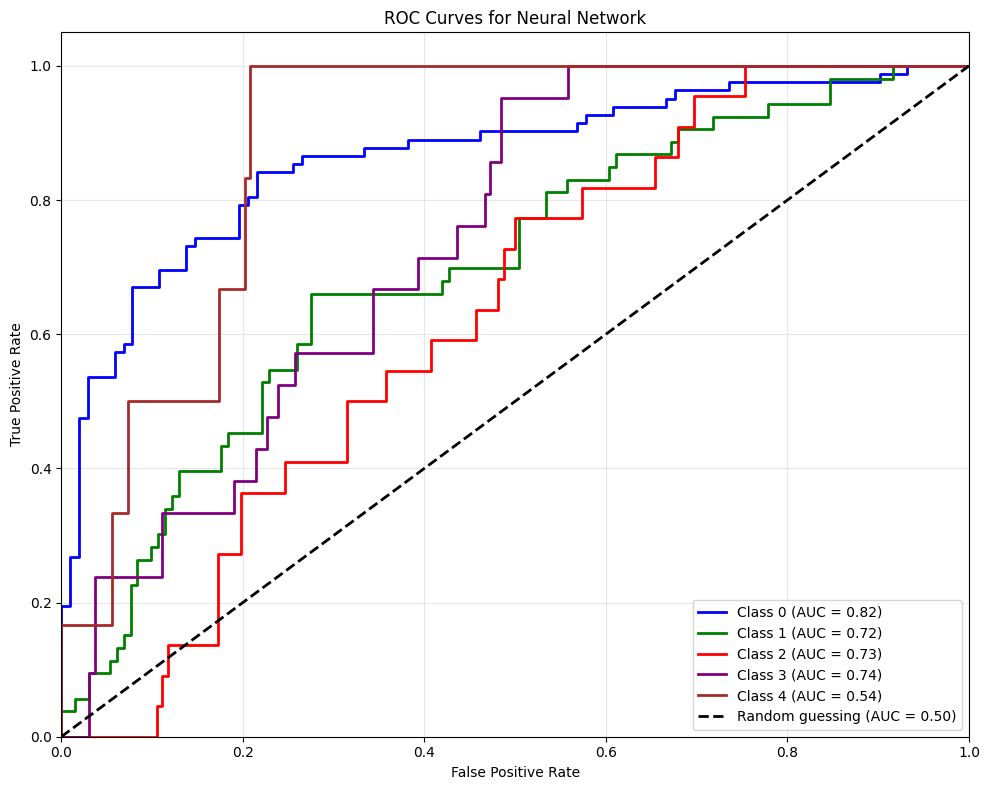

AUC Scores for Neural Network:
  Class_0: 0.8204
  Class_1: 0.7163
  Class_2: 0.7308
  Class_3: 0.7396
  Class_4: 0.5399


In [ ]:
print("\nROC Curve Analysis:")
print("=" * 30)

for model_name, result in model_results.items():
    model = result['model']
    auc_data = result['auc_scores']

    if auc_data:
        plt.figure(figsize=(10, 8))

        y_prob = model.predict_proba(X_test)
        n_classes = y_prob.shape[1]

        colors = ['blue', 'green', 'red', 'purple', 'brown', 'orange', 'pink', 'gray']
        for i in range(n_classes):
            if i < len(colors):
                y_binary = (y_test == i).astype(int)
                fpr, tpr, _ = roc_curve(y_binary, y_prob[:, i])

                plt.plot(fpr, tpr, color=colors[i], lw=2,
                         label=f'Class {i} (AUC = {auc_data[f"Class_{i}"]:.2f})')

        plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random guessing (AUC = 0.50)')

        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC Curves for {model_name}')
        plt.legend(loc="lower right")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        print(f"AUC Scores for {model_name}:")
        for class_name, auc_score in auc_data.items():
            print(f"  {class_name}: {auc_score:.4f}")
    else:
        print(f"No ROC curve data available for {model_name}")

**<h1>Conclusion</h1>**

In [ ]:
print("\n--- Final Model Comparison ---")

comparison_data = []
for model_name, result in model_results.items():
    test_metrics, test_cm, test_auc = evaluate_model(result['model'], X_test, y_test, model_name)

    comparison_data.append({
        'Model': model_name,
        'Test Accuracy': test_metrics['Accuracy'],
        'Precision': test_metrics['Precision'],
        'Recall': test_metrics['Recall'],
        'F1-Score': test_metrics['F1-Score']
    })

final_comparison = pd.DataFrame(comparison_data)
final_comparison.set_index('Model', inplace=True)

print(final_comparison)

# best model based on test accuracy
best_model_name = final_comparison['Test Accuracy'].idxmax()
best_accuracy = final_comparison.loc[best_model_name, 'Test Accuracy']

print(f"\nBest performing model: {best_model_name} with test accuracy of {best_accuracy:.4f}")


--- Final Model Comparison ---
                     Test Accuracy  Precision    Recall  F1-Score
Model                                                            
KNN                       0.597826   0.549010  0.597826  0.571264
Logistic Regression       0.581522   0.472159  0.581522  0.519826
Neural Network            0.532609   0.538419  0.532609  0.534690

Best performing model: KNN with test accuracy of 0.5978
